# 20 - Steps, impulses, and convolution

**MATH 331 - Differential Equations.** Lecture plan, Unit 11: Session 25 (Sections 2-4) and Session 26
(Sections 5-6).

**References:** J. Lebl, *Notes on Diffy Qs*, Section 6.1 (Example 6.1.4), Sections 6.2, 6.3 and 6.4, and
exercises of Chapter 6; notebooks 07, 14, 15, 19; videos R03 (integration by parts), R04 (partial
fractions).

**What you will learn**
1. A force that switches on or off is written with the step function $u(t - a)$, and a switch at the time
   $a$ becomes a factor $e^{-as}$ on the $s$ side: the four steps of notebook 19 then work unchanged.
2. A very short, very strong push (a blow) is the limit of short pulses, the delta function: it changes
   the velocity at once.
3. The response to a blow, the impulse response, gives the response to every other input by one
   integral, the convolution.

## 1. Before you start

**What you need** (notebook 19): the table of transforms with the first shifting property; the four steps,
with $\mathcal{L}\{x''\} = s^2X(s) - s\,x(0) - x'(0)$; `ol.laplace_numeric(f, s)`, the transform computed as
an integral. From notebook 07: free motion, $mx'' + cx' + kx = 0$, and `ol.free_response`.

**Conventions (the whole notebook).**
* $t \ge 0$ is the time, and $t = 0$ is when the problem starts; $s$ is a real number; functions of time
  are in lower case and their transforms in upper case, as in notebook 19.
* $u(t - a)$ is the **unit step** (Lebl; also called the Heaviside function): 0 before the time $a$, 1
  from $a$ on. This $u$ is not the $u_1$, $u_2$ of variation of parameters (notebook 14), and not the
  unknowns of a first-order system (notebook 17).
* **At the jump itself** the value is 1: $u(0) = 1$ (Lebl). Nothing depends on this choice: one point has
  no area under it, so it changes no transform and no solution (Lebl's remark after his Theorem 6.1.3).
* The Greek letters are read $\tau$ "tau", $\delta$ "delta", $\varphi$ "phi"; the labels of the figures
  write them so.
* **From rest** means here: at its rest position and not moving, $x(0) = 0$ and $x'(0) = 0$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: step, convolution, impulse_response, laplace_numeric, forced_response, free_response,
# check, check_formula).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


In [2]:
# SymPy's letters t and s, for formulas; a number chosen for s has its own name (S_CHECKS, S_PULSE, ...)
t, s = sp.symbols("t s", positive=True)


def u(x):
    # the unit step u, written as in the text: u(t - 2) in a formula typed with SymPy, and
    # u(times - 2) with numbers or arrays (the same as ol.step(times, 2)). At the jump it is 1.
    # (One argument: write u(t - 1), not u(t, 1).)
    if isinstance(x, sp.Basic):
        return sp.Heaviside(x, 1)
    return ol.step(x)


step_in_formulas = u                        # a second name for u: Exercise 2 uses it to put u back

## 2. The step function

(Session 25.) *In class:* the step, the two recipes for building functions, the figures; the second
shifting property in words, with its figure, the mistake of Section 3 and "from right to left"; the
rocket of Section 4 with its figure and its slider. *At home:* Exercise 4(b), and the computations in
the answers (Section 9).

**A switch.** A force that starts at a certain time needs a function that is 0 before that time and 1
after it. *Lebl, Example 6.1.4,* the unit step:

$$ u(t) = \begin{cases} 0 & \text{if } t < 0, \\ 1 & \text{if } t \ge 0, \end{cases} \qquad\text{so}\qquad
   u(t - a) = \begin{cases} 0 & \text{if } t < a, \\ 1 & \text{if } t \ge a. \end{cases} $$

Read $u(t - a)$ as "the switch that closes at the time $a$": what is inside the parentheses is negative
before $a$, and zero or positive from $a$ on. For $a = 2$: $u(0 - 2) = u(-2) = 0$, $u(1.9 - 2) = u(-0.1) = 0$,
$u(2 - 2) = u(0) = 1$, $u(5 - 2) = u(3) = 1$. In code, `ol.step(t, a)` is $u(t - a)$ for numbers and
arrays; in a formula typed with SymPy it is `u(t - a)`, with the `u` of the cell above (which also
accepts numbers: `u(times - 2)` is `ol.step(times, 2)`).

    t   u(t - 2)
    0      0
    1      0
  1.9      0
    2      1
  2.1      1
    5      1


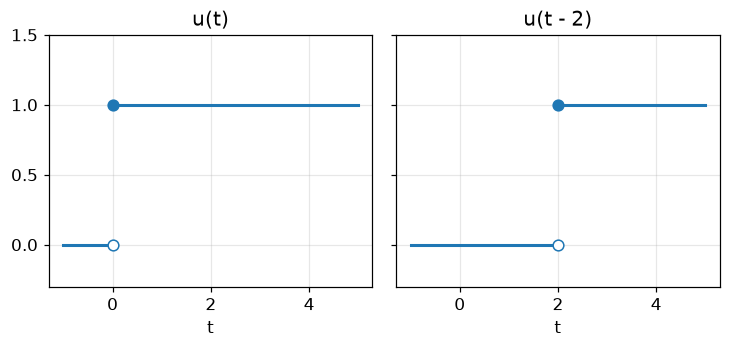

In [3]:
A_SWITCH = 2.0                              # the switch closes at this time (try another, between 0 and 4)
TIMES_SHOWN = (0.0, 1.0, 1.9, 2.0, 2.1, 5.0)
print(f"    t   u(t - {A_SWITCH:g})")
for time in TIMES_SHOWN:
    print(f"{time:5g} {float(ol.step(time, A_SWITCH)):6g}")
    # the same by cases: 0 before the time A_SWITCH, 1 from that time on (the jump included)
    assert float(ol.step(time, A_SWITCH)) == (1.0 if time >= A_SWITCH else 0.0)

# drawing code: you can skip reading it
WIDE_FIGURE = (7.0, 3.3)                    # two panels side by side
CURVE_POINTS = 400
T_STEP = (-1.0, 5.0)                        # the part of the t axis that is drawn
STEP_HEIGHT = (-0.3, 1.5)
POINT_SIZE = 7                              # markers: a point


def draw_pieces(ax, function, edges, style="-", color="C0", label=None, width=2):
    # the graph of a function that jumps at the inner edges: each piece is drawn alone, so that no
    # line joins the two sides of a jump
    for index in range(len(edges) - 1):
        times = np.linspace(edges[index], edges[index + 1], CURVE_POINTS, endpoint=False)
        # (+ 0 * times: a function that returns one number, such as 1.0, gets the shape of times)
        ax.plot(times, function(times) + 0 * times, style, color=color, linewidth=width,
                label=label if index == 0 else None)


fig, panels = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
for ax, switch in zip(panels, (0.0, A_SWITCH)):
    draw_pieces(ax, lambda times: ol.step(times, switch), (T_STEP[0], switch, T_STEP[1]))
    ax.plot(switch, 0.0, "o", color="C0", markerfacecolor="white", markersize=POINT_SIZE)    # not this value
    ax.plot(switch, 1.0, "o", color="C0", markersize=POINT_SIZE)                             # but this one
    ax.set_ylim(*STEP_HEIGHT)
    ax.set_xlabel("t")
    ax.set_title("u(t)" if switch == 0 else f"u(t - {switch:g})")
plt.tight_layout()
plt.show()

*The plot shows* $u(t)$ (left) and $u(t - 2)$ (right): 0, then 1. The full dot is the value at the jump
(1), the empty dot the value that is not taken (0).

**Building functions with switches** (Lebl, Section 6.2). Two recipes (a third, for a function given by
cases, is in Exercise 2(a)).
* *Switch a function on:* $f(t)\,u(t - a)$ is 0 before $a$ and $f(t)$ from $a$ on. Lebl's signal that
  starts at $t = \pi$ is $u(t - \pi)\sin t$.
* *A window:* $u(t - a) - u(t - b)$, with $a < b$, is 1 for $a \le t < b$ and 0 elsewhere. With $a = 1$,
  $b = 2$: at $t = 0.5$ it is $0 - 0 = 0$; at $t = 1.5$ it is $1 - 0 = 1$; at $t = 2.5$ it is
  $1 - 1 = 0$.

the window at t = [0.5 1.5 2.5]: [0. 1. 0.]


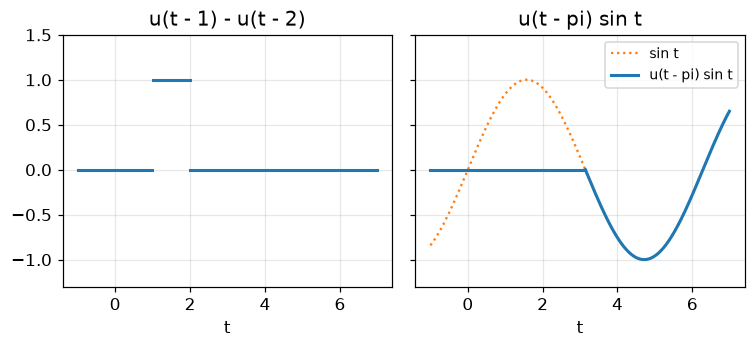

In [4]:
ON, OFF = 1.0, 2.0                          # Lebl's window is 1 for 1 <= t < 2
SIGNAL_START = np.pi                        # his signal starts at t = pi


def window(t, a, b):
    return ol.step(t, a) - ol.step(t, b)    # 1 for a <= t < b, and 0 elsewhere


def late_signal(t):
    return ol.step(t, SIGNAL_START) * np.sin(t)             # sin t, received from t = pi on


# the two functions against their definition by cases, at many times
T_BUILD = (-1.0, 7.0)                       # the t axis of the two panels
times = np.linspace(*T_BUILD, 2 * CURVE_POINTS + 1)
assert np.array_equal(window(times, ON, OFF), np.where((times >= ON) & (times < OFF), 1.0, 0.0))
assert np.array_equal(late_signal(times), np.where(times >= SIGNAL_START, np.sin(times), 0.0))
HAND_TIMES = np.array([0.5, 1.5, 2.5])      # the times of the text
print(f"the window at t = {HAND_TIMES}: {window(HAND_TIMES, ON, OFF)}")

# drawing code: you can skip reading it
BUILD_HEIGHT = (-1.3, 1.5)
fig, panels = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
draw_pieces(panels[0], lambda times: window(times, ON, OFF), (T_BUILD[0], ON, OFF, T_BUILD[1]))
panels[0].set_title("u(t - 1) - u(t - 2)")
panels[1].plot(times, np.sin(times), ":", color="C1", linewidth=1.5, label="sin t")
draw_pieces(panels[1], late_signal, (T_BUILD[0], SIGNAL_START, T_BUILD[1]), label="u(t - pi) sin t")
panels[1].set_title("u(t - pi) sin t")
panels[1].legend(loc="upper right")
for ax in panels:
    ax.set_ylim(*BUILD_HEIGHT)
    ax.set_xlabel("t")
plt.tight_layout()
plt.show()

*The plot shows* a window that is 1 from $t = 1$ to $t = 2$ (left), and $\sin t$ (dotted) with the signal
that is 0 until $t = \pi$ and $\sin t$ after (right).

**The transform of a step** (Lebl, Example 6.1.4; the row of Table 6.1.1 that notebook 19 left for this
notebook): for $a \ge 0$ and $s > 0$,

$$ \mathcal{L}\{u(t - a)\} = \frac{e^{-as}}{s} $$

(the integral, which starts at $a$, is in Section 9). With $a = 0$ this is $1/s$, the row of the function
1. **A switch at the time $a$ has become the factor $e^{-as}$.** The code compares the formula with the
integral (`breaks=[a]` tells `ol.laplace_numeric` where the function jumps).

In [5]:
S_CHECKS = (0.5, 1.0, 4.0)                  # the values of s at which a formula is compared with the integral
print(f"L{{u(t - {A_SWITCH:g})}}:    s   the integral   e^(-as)/s")
for s_value in S_CHECKS:
    by_integral = ol.laplace_numeric(lambda t: ol.step(t, A_SWITCH), s_value, breaks=[A_SWITCH])
    by_formula = np.exp(-A_SWITCH * s_value) / s_value
    print(f"{s_value:19g} {by_integral:14.8f} {by_formula:11.8f}")
    # np.isclose: equal to about 5 significant digits (to 1e-8 for very small numbers)
    assert np.isclose(by_integral, by_formula)

L{u(t - 2)}:    s   the integral   e^(-as)/s
                0.5     0.73575888  0.73575888


                  1     0.13533528  0.13533528
                  4     0.00008387  0.00008387


## 3. The second shifting property

(Session 25.) **In words first:** delay a function by $a$ (start it $a$ later, with nothing before), and
its transform is multiplied by $e^{-as}$.

The delayed function is $f(t - a)\,u(t - a)$: the graph of $f$ moved by $a$ to the right, and 0 before
$a$. For $f(t) = t^2$ and $a = 1$ it is $(t - 1)^2u(t - 1)$: at $t = 3$ its value is $f(2) = 4$, at
$t = 0.5$ it is 0.

**The second shifting property** (Lebl, formula (6.2.2); the theory exercise of Session 25): for
$a \ge 0$, and for the values of $s$ at which $F(s)$ exists,

$$ \mathcal{L}\{f(t - a)\,u(t - a)\} = e^{-as}F(s) . $$

(Why: Exercise 4(b).) Example: $\sin t$ delayed by 2 is $\sin(t - 2)\,u(t - 2)$, with the transform
$e^{-2s}\cdot\dfrac{1}{s^2 + 1}$.

**The usual mistake: cut off is not delayed.** $t\,u(t - 1)$ is the function $t$ with its part before
$t = 1$ cut off. It is not $t$ delayed by 1: that is $(t - 1)\,u(t - 1)$, which starts from 0 at
$t = 1$. The property needs the same $t - a$ inside $f$ and inside $u$. So write $t$ with $t - 1$ first:
$t = (t - 1) + 1$, and

$$ t\,u(t - 1) = (t - 1)\,u(t - 1) + 1\cdot u(t - 1) \quad\Longrightarrow\quad
   \mathcal{L}\{t\,u(t - 1)\} = e^{-s}\frac{1}{s^2} + e^{-s}\frac1s
   = e^{-s}\Big(\frac{1}{s^2} + \frac1s\Big) , $$

a delayed $t$ plus a delayed 1. The wrong answer, $e^{-s}/s^2$, forgets the second term. (At $t = 2$:
$t\,u(t - 1) = 2$, and $(t - 1)\,u(t - 1) = 1$.)

    s   L{sin(t - 2) u(t - 2)}   e^(-as)/(s^2 + 1)
  0.5            0.29430355          0.29430355
    1            0.06766764          0.06766764


    4            0.00001973          0.00001973

    s   L{t u(t - 1)}   the right formula   the wrong formula
  0.5     3.63918396          3.63918396          2.42612264
    1     0.73575888          0.73575888          0.36787944


    4     0.00572364          0.00572364          0.00114473


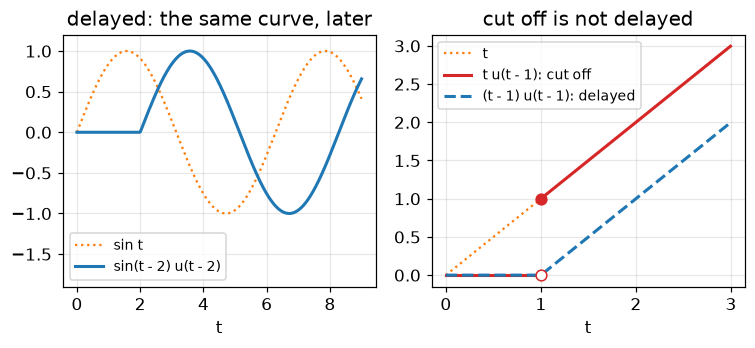

In [6]:
DELAY = 2.0                                 # sin t is delayed by this time (try another one, 0 or more)


def delayed_sine(t):
    return np.sin(t - DELAY) * ol.step(t, DELAY)            # sin(t - a) u(t - a)


CUT = 1.0                                   # the 1 of t u(t - 1) in the text (keep it)


def cut_off(t):
    return t * ol.step(t, CUT)              # t u(t - 1)


def delayed_ramp(t):
    return (t - CUT) * ol.step(t, CUT)      # (t - 1) u(t - 1)


print(f"    s   L{{sin(t - {DELAY:g}) u(t - {DELAY:g})}}   e^(-as)/(s^2 + 1)")
for s_value in S_CHECKS:
    of_delayed = ol.laplace_numeric(delayed_sine, s_value, breaks=[DELAY])
    rule = np.exp(-DELAY * s_value) / (s_value ** 2 + 1)
    print(f"{s_value:5g} {of_delayed:21.8f} {rule:19.8f}")
    assert np.isclose(of_delayed, rule)
print()
print("    s   L{t u(t - 1)}   the right formula   the wrong formula")
for s_value in S_CHECKS:
    of_cut_off = ol.laplace_numeric(cut_off, s_value, breaks=[CUT])
    right = np.exp(-CUT * s_value) * (1 / s_value ** 2 + CUT / s_value)     # t = (t - 1) + 1
    wrong = np.exp(-CUT * s_value) / s_value ** 2                           # as if t u(t - 1) were delayed
    print(f"{s_value:5g} {of_cut_off:14.8f} {right:19.8f} {wrong:19.8f}")
    assert np.isclose(of_cut_off, right)
    # (with CUT = 0 nothing is cut off, and the two formulas are the same)
    assert CUT == 0 or not np.isclose(of_cut_off, wrong), "the wrong formula agrees with the integral"

# drawing code: you can skip reading it
T_SHIFT = (0.0, 9.0)
SINE_HEIGHT = (-1.9, 1.2)                   # room below the curves for the legend
times = np.linspace(*T_SHIFT, CURVE_POINTS)
fig, (left, right_panel) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
left.plot(times, np.sin(times), ":", color="C1", linewidth=1.5, label="sin t")
left.plot(times, delayed_sine(times), "-", color="C0", linewidth=2,
          label=f"sin(t - {DELAY:g}) u(t - {DELAY:g})")
left.set_ylim(*SINE_HEIGHT)
left.set_title("delayed: the same curve, later")
left.legend(loc="lower left")
T_RAMP = (0.0, 3.0)
draw_pieces(right_panel, lambda times: times, T_RAMP, ":", "C1", "t", 1.5)
draw_pieces(right_panel, cut_off, (T_RAMP[0], CUT, T_RAMP[1]), "-", "C3", "t u(t - 1): cut off")
draw_pieces(right_panel, delayed_ramp, T_RAMP, "--", "C0", "(t - 1) u(t - 1): delayed")
right_panel.plot(CUT, 0.0, "o", color="C3", markerfacecolor="white", markersize=POINT_SIZE)     # not this
right_panel.plot(CUT, float(cut_off(CUT)), "o", color="C3", markersize=POINT_SIZE)              # but this one
right_panel.set_title("cut off is not delayed")
right_panel.legend(loc="upper left")
for ax in (left, right_panel):
    ax.set_xlabel("t")
plt.tight_layout()
plt.show()

*The plot shows*, left, $\sin t$ (dotted) and the same curve started 2 later (solid), which is 0 until
$t = 2$. Right: $t\,u(t - 1)$ (solid) jumps from 0 (empty dot) to 1 (full dot) at $t = 1$ and then follows
the dotted line $t$; the delayed $(t - 1)\,u(t - 1)$ (dashed) starts from 0 at $t = 1$ and stays 1 below
it. In the second table the integral agrees with the right formula; at $s = 1$ the wrong one gives half
of it.

**From right to left.** A factor $e^{-as}$ in a transform means a delay: $e^{-as}F(s)$ is the transform
of $f(t - a)\,u(t - a)$.
1. Put $e^{-as}$ aside.
2. Invert what is left, $F(s)$: this gives $f(t)$.
3. Write $t - a$ in place of every $t$ of $f$, and multiply by $u(t - a)$.

Example: $\dfrac{e^{-2s}}{s^2}$. Without $e^{-2s}$ it is $1/s^2$, the transform of $t$; so the answer is
$(t - 2)\,u(t - 2)$: 0 until $t = 2$, and 3 at $t = 5$.

## 4. A force that switches on and off

(Session 25.) *Lebl, Example 6.2.2:* a mass on a spring, $x'' + x = f(t)$, $x(0) = 0$, $x'(0) = 0$,
where $f(t) = 1$ for $1 \le t < 5$ and 0 otherwise: "a rocket is fired for 4 seconds starting at
$t = 1$".

$x(t)$ is the displacement of the mass, positive when the spring is stretched, as a positive force
stretches it; the mass starts from rest; Lebl gives no units.

The force is a window: $f(t) = u(t - 1) - u(t - 5)$, on at $t = 1$ and off at $t = 5$. The four steps:
1. Transform. On the left $s^2X(s) - s\,x(0) - x'(0) + X(s) = (s^2 + 1)X(s)$, since $x(0) = x'(0) = 0$. On
   the right, the transform of a step, twice:
   $(s^2 + 1)X(s) = \dfrac{e^{-s}}{s} - \dfrac{e^{-5s}}{s}$.
2. Solve (divide by $s^2 + 1$): $X(s) = e^{-s}\,\dfrac{1}{s(s^2 + 1)} - e^{-5s}\,\dfrac{1}{s(s^2 + 1)}$.
3. Partial fractions of what stands beside the exponentials:
   $\dfrac{1}{s(s^2 + 1)} = \dfrac{A}{s} + \dfrac{Bs + C}{s^2 + 1}$. Multiply by $s(s^2 + 1)$:
   $1 = A(s^2 + 1) + (Bs + C)s = (A + B)s^2 + Cs + A$. Equal powers of $s$: $A + B = 0$, $C = 0$, $A = 1$,
   so $B = -1$:
   $\dfrac{1}{s(s^2 + 1)} = \dfrac1s - \dfrac{s}{s^2 + 1}$, the transform of $g(t) = 1 - \cos t$: call it
   $G(s)$, so that $X(s) = e^{-s}G(s) - e^{-5s}G(s)$.
4. Invert, from right to left (Section 3). The term $e^{-s}G(s)$ is $g$ delayed by 1,
   $g(t - 1)\,u(t - 1) = \big(1 - \cos(t - 1)\big)u(t - 1)$; the term $e^{-5s}G(s)$ is $g$ delayed by 5,
   $\big(1 - \cos(t - 5)\big)u(t - 5)$. So

$$ x(t) = \big(1 - \cos(t - 1)\big)\,u(t - 1) - \big(1 - \cos(t - 5)\big)\,u(t - 5)
   \qquad\text{(the book's answer).} $$

Read it by cases. For $t < 1$ both steps are 0: $x = 0$. For $1 \le t < 5$ only the first is 1:
$x = 1 - \cos(t - 1)$. For $t \ge 5$ both are 1: $x = 1 - \cos(t - 1) - 1 + \cos(t - 5)
= \cos(t - 5) - \cos(t - 1)$.

step 3: 1/(s (s^2 + 1)) = -s/(s**2 + 1) + 1/s
step 4, by SymPy: x(t) = cos(t - 5)*Heaviside(t - 5) - cos(t - 1)*Heaviside(t - 1) - Heaviside(t - 5) + Heaviside(t - 1)
(Heaviside is SymPy's name for u; these are the two terms of the text, multiplied out)


ol.forced_response: largest difference from x(t) 3e-11
while the rocket fires: x between 0.00 and 2.00; at the stop x = 1.65; after it: x between -1.82 and 1.82


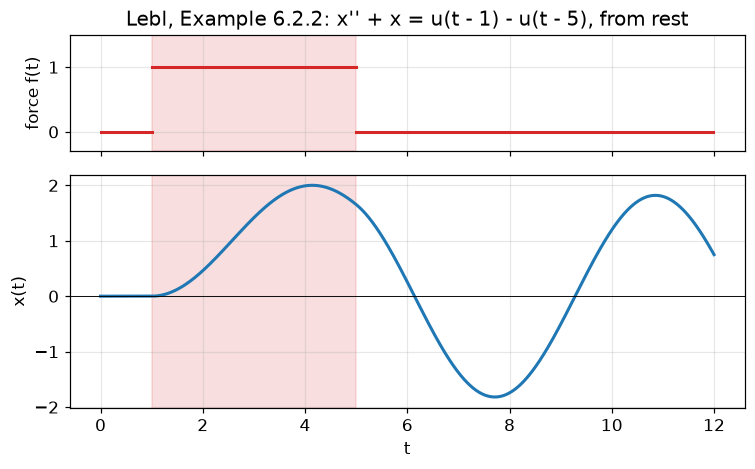

In [7]:
# to try another firing time use the slider below: this cell compares each step with the formulas of the text
ROCKET_ON, ROCKET_OFF = 1.0, 5.0            # Lebl, Example 6.2.2: the rocket fires for 1 <= t < 5
EQUATION_622 = (1.0, 0.0, 1.0)              # 1 x'' + 0 x' + 1 x = f(t)


def rocket_force(t, off=ROCKET_OFF):
    return ol.step(t, ROCKET_ON) - ol.step(t, off)          # 1 while the rocket fires, 0 otherwise


def rocket_response(t, off=ROCKET_OFF):
    # the answer of step 4: two delayed copies of g(t) = 1 - cos t, one for each switch
    return ((1 - np.cos(t - ROCKET_ON)) * ol.step(t, ROCKET_ON)
            - (1 - np.cos(t - off)) * ol.step(t, off))


TEXT_ROCKET = ("this cell checks the formulas of the text, which are for a rocket fired from t = 1 to t = 5: "
               "put 1.0 and 5.0 back, and use the slider below for other firing times")
fraction = 1 / (s * (s ** 2 + 1))
print("step 3: 1/(s (s^2 + 1)) =", sp.apart(fraction, s))
assert sp.simplify(sp.apart(fraction, s) - (1 / s - s / (s ** 2 + 1))) == 0       # the fractions of the text
on, off = sp.nsimplify(ROCKET_ON), sp.nsimplify(ROCKET_OFF)                       # 1 and 5, for SymPy
X_622 = (sp.exp(-on * s) - sp.exp(-off * s)) * fraction                           # step 2
by_sympy = sp.inverse_laplace_transform(X_622, s, t)                              # SymPy's own inverse
print("step 4, by SymPy: x(t) =", by_sympy)
print("(Heaviside is SymPy's name for u; these are the two terms of the text, multiplied out)")

# checking code: you can skip reading it; read what it prints
T_ROCKET = 12.0
CHECK_POINTS = 13                           # times at which the slower checks are made
check_times = np.linspace(0.0, T_ROCKET, CHECK_POINTS)
assert np.allclose(sp.lambdify(t, by_sympy)(check_times), rocket_response(check_times)), TEXT_ROCKET
for s_value in S_CHECKS:                    # the answer, transformed forward, is X(s)
    forward = ol.laplace_numeric(rocket_response, s_value, breaks=[ROCKET_ON, ROCKET_OFF])
    assert np.isclose(forward, float(X_622.subs(s, s_value))), TEXT_ROCKET
# a third answer, without transforms: variation of parameters (notebook 14)
third = ol.forced_response(check_times, *EQUATION_622, lambda t: float(rocket_force(t)))
print("ol.forced_response: largest difference from x(t)",
      f"{np.max(np.abs(third - rocket_response(check_times))):.0e}")
FORCED_AGREEMENT = 1e-6                     # ol.forced_response integrates across the two jumps of the force
assert np.allclose(third, rocket_response(check_times), atol=FORCED_AGREEMENT), TEXT_ROCKET
FINE_POINTS = 12001                         # a point every 0.001: the numbers printed below are read from it
times = np.linspace(0.0, T_ROCKET, FINE_POINTS)
while_firing = rocket_response(times[(times >= ROCKET_ON) & (times < ROCKET_OFF)])
after_it = rocket_response(times[times >= ROCKET_OFF])
print(f"while the rocket fires: x between {while_firing.min():.2f} and {while_firing.max():.2f}; "
      f"at the stop x = {float(rocket_response(ROCKET_OFF)):.2f}; "
      f"after it: x between {after_it.min():.2f} and {after_it.max():.2f}")

# drawing code: you can skip reading it
TALL_FIGURE = (7.0, 4.4)                    # two panels, one above the other
FORCE_HEIGHT = (-0.3, 1.5)
SHADE = 0.15                                # how dark the time of firing is shaded
fig, (above, below) = plt.subplots(2, 1, figsize=TALL_FIGURE, sharex=True, height_ratios=(1, 2))
draw_pieces(above, rocket_force, (0.0, ROCKET_ON, ROCKET_OFF, T_ROCKET), "-", "C3")
above.set_ylim(*FORCE_HEIGHT)
above.set_ylabel("force f(t)")
above.set_title(f"Lebl, Example 6.2.2: x'' + x = u(t - {ROCKET_ON:g}) - u(t - {ROCKET_OFF:g}), from rest")
below.plot(times, rocket_response(times), "-", color="C0", linewidth=2)
below.axhline(0.0, color="black", linewidth=0.6)
for ax in (above, below):
    ax.axvspan(ROCKET_ON, ROCKET_OFF, color="C3", alpha=SHADE)
below.set_ylabel("x(t)")
below.set_xlabel("t")
plt.tight_layout()
plt.show()

*The plot shows* the force (above) and the displacement (below); the rocket fires in the shaded time.
The mass does not move until $t = 1$. While the rocket fires it moves out to $x = 2$ (at
$t = 1 + \pi \approx 4.14$) and starts to come back: an oscillation about $x = 1$, where the force of
the spring, $1 \cdot x$, equals the force 1 of the rocket. When the rocket stops, at $t = 5$, the mass is
at $x = 1.65$: it keeps oscillating for ever, now about $x = 0$, between $-1.82$ and $1.82$.

**Slider: how long the rocket fires.** The rocket starts at $t = 1$ and now fires for $d$ seconds, $d$
from 0.5 to 8. The title gives the largest $|x|$ after the stop. Before moving it: the mass was pushed;
is there a firing time $d$ after which it stays at rest? (Lebl, Exercise 6.2.10.)

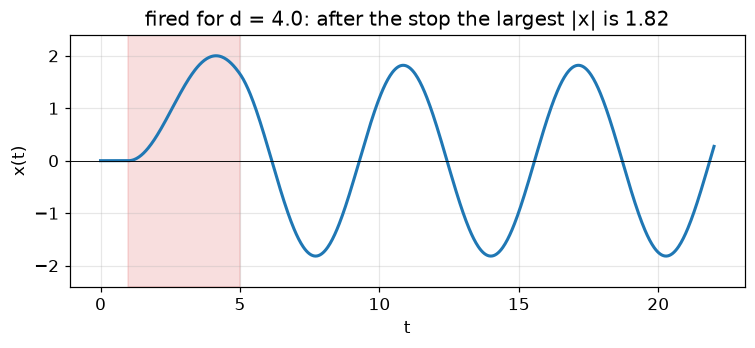

In [8]:
DEFAULT_D = ROCKET_OFF - ROCKET_ON          # the 4 seconds of the example
D_RANGE = (0.5, 8.0, 0.1)                   # minimum, maximum, step
T_SLIDER_1 = 22.0                           # the t axis
SINGLE_FIGURE = (7.0, 3.3)
ROCKET_HEIGHT = (-2.4, 2.4)
PERIOD = 2 * np.pi                          # of the free oscillation of x'' + x = 0
PERIOD_POINTS = 2001


def largest_after(d):
    # the largest |x| after the stop, measured on one period of the oscillation that follows it
    one_period = np.linspace(ROCKET_ON + d, ROCKET_ON + d + PERIOD, PERIOD_POINTS)
    return float(np.max(np.abs(rocket_response(one_period, ROCKET_ON + d))))


def plot_rocket(d=DEFAULT_D):
    # the displacement for a rocket that fires from t = 1 for d seconds (shaded)
    grid = np.linspace(0.0, T_SLIDER_1, 2 * CURVE_POINTS)
    fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
    ax.axvspan(ROCKET_ON, ROCKET_ON + d, color="C3", alpha=SHADE)
    ax.plot(grid, rocket_response(grid, ROCKET_ON + d), "-", color="C0", linewidth=2)
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_ylim(*ROCKET_HEIGHT)
    ax.set_xlabel("t")
    ax.set_ylabel("x(t)")
    ax.set_title(f"fired for d = {d:.1f}: after the stop the largest |x| is {largest_after(d):.2f}")
    plt.tight_layout()
    plt.show()


plot_rocket()

In [9]:
interact(plot_rocket, d=FloatSlider(value=DEFAULT_D, min=D_RANGE[0], max=D_RANGE[1], step=D_RANGE[2],
                                    description="d", continuous_update=False));

interactive(children=(FloatSlider(value=4.0, continuous_update=False, description='d', max=8.0, min=0.5), Outp...

*The static plot shows*, for $d = 4$ (the example), the time of firing (shaded) and $x(t)$: after the
stop the largest $|x|$ is 1.82.

(Answer: yes, $d = 2\pi \approx 6.28$. On the slider the nearest position is 6.3, where the title shows
0.02. While the rocket fires, $x = 1 - \cos(t - 1)$: an oscillation about $x = 1$ with period $2\pi$ that
starts from rest at $x = 0$. After exactly one period the mass is back at $x = 0$ with velocity 0: if the
rocket stops at that instant, nothing moves the mass any more. The largest $|x|$ after the stop, for
every $d$, by a formula: the answer of Exercise 3(ii).)

In [10]:
# checking code: you can skip reading it; read what it prints
# (2 |sin(d/2)| is the formula of the answer of Exercise 3(ii))
GRID_AGREEMENT = 1e-5                       # the largest value on a grid against the true amplitude
SHOWN_D = (0.5, np.pi, 4.0, 6.2, 6.3, PERIOD, 8.0)
for d in np.arange(D_RANGE[0], D_RANGE[1] + D_RANGE[2] / 2, D_RANGE[2]):       # every position of the slider
    assert np.isclose(largest_after(d), 2 * abs(np.sin(d / 2)), atol=GRID_AGREEMENT)
    later = ROCKET_ON + d + np.linspace(0.0, PERIOD, CHECK_POINTS)             # the formula with one sine
    assert np.allclose(rocket_response(later, ROCKET_ON + d),
                       2 * np.sin(d / 2) * np.sin(later - ROCKET_ON - d / 2))
for d in SHOWN_D:
    print(f"d = {d:.4g}: largest |x| after the stop {largest_after(d):.4f}, 2 |sin(d/2)| = "
          f"{2 * abs(np.sin(d / 2)):.4f}")

d = 0.5: largest |x| after the stop 0.4948, 2 |sin(d/2)| = 0.4948
d = 3.142: largest |x| after the stop 2.0000, 2 |sin(d/2)| = 2.0000
d = 4: largest |x| after the stop 1.8186, 2 |sin(d/2)| = 1.8186
d = 6.2: largest |x| after the stop 0.0832, 2 |sin(d/2)| = 0.0832
d = 6.3: largest |x| after the stop 0.0168, 2 |sin(d/2)| = 0.0168
d = 6.283: largest |x| after the stop 0.0000, 2 |sin(d/2)| = 0.0000
d = 8: largest |x| after the stop 1.5136, 2 |sin(d/2)| = 1.5136


## 5. From a short pulse to a blow

(Session 26.) *In class:* the pulses and their slider; the delta function; the blow on a mass in words
and by the four steps, with its figure; what the impulse response is; in Section 6 the definition of the
convolution, how to read it, $1 * 1 = t$, the table and the figure, and the response as a sum of blows.
*At home:* the numbers of the tables, and the computations in the answers (Section 9).

**Conventions (this section).** $b$ is the width of a pulse (Lebl's letter); it is not a coefficient: the
equation of the mass is written $mx'' + cx' + kx = f(t)$, as in notebook 07.

**A unit pulse** (Lebl, Section 6.4.1) of width $b$ is a force of height $1/b$ that acts for
$0 \le t < b$:

$$ \varphi_b(t) = \frac{u(t) - u(t - b)}{b} . $$

Its area is width times height, $b \cdot \dfrac1b = 1$, for every $b$: with $b = 0.5$ the height is 2,
with $b = 0.1$ it is 10. By linearity and the transform of a step,

$$ \mathcal{L}\{\varphi_b(t)\} = \frac1b\Big(\frac1s - \frac{e^{-bs}}{s}\Big) = \frac{1 - e^{-bs}}{bs} , $$

which tends to 1 as $b$ shrinks (the table below, for home).

In [11]:
S_PULSE = 1.0                               # the value of s (try another one, larger than 0)
WIDTHS = (2.0, 1.0, 0.5, 0.1, 0.01)         # the widths b
assert S_PULSE > 0, "S_PULSE must be larger than 0"


def unit_pulse(t, b):
    return (ol.step(t) - ol.step(t, b)) / b                 # height 1/b for 0 <= t < b: area 1


print(f"the transform of the unit pulse at s = {S_PULSE:g}")
print("     b   height 1/b   the integral   (1 - e^(-bs))/(bs)")
for b in WIDTHS:
    by_integral = ol.laplace_numeric(lambda t: unit_pulse(t, b), S_PULSE, breaks=[b])
    by_formula = (1 - np.exp(-b * S_PULSE)) / (b * S_PULSE)
    print(f"{b:6g} {1 / b:10g} {by_integral:14.6f} {by_formula:16.6f}")
    assert np.isclose(by_integral, by_formula)

the transform of the unit pulse at s = 1
     b   height 1/b   the integral   (1 - e^(-bs))/(bs)
     2        0.5       0.432332         0.432332


     1          1       0.632121         0.632121
   0.5          2       0.786939         0.786939


   0.1         10       0.951626         0.951626
  0.01        100       0.995017         0.995017


*The table shows* that the transform of the pulse comes nearer and nearer to 1 as $b$ shrinks.

**Slider: a shorter, taller pulse.** The mass on the spring of Section 4, at rest, is pushed by the unit
pulse: $x'' + x = \varphi_b(t)$, $x(0) = 0$, $x'(0) = 0$, with $b$ from 2 down to 0.05. The height of the
pulse grows from 0.5 to 20; its area stays 1. Before moving it: as the pulse gets shorter and taller,
does the response grow without bound?

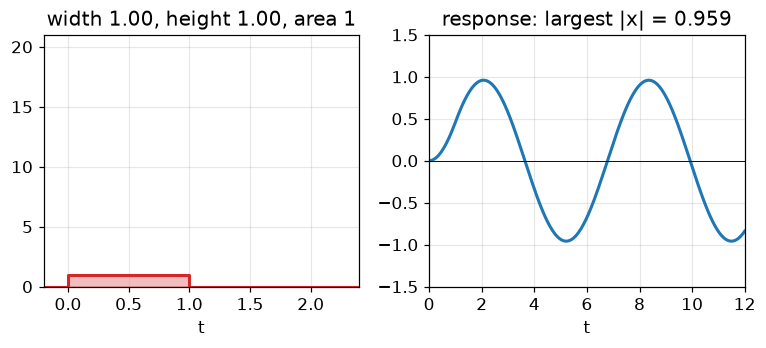

In [12]:
DEFAULT_B = 1.0
B_RANGE = (0.05, 2.0, 0.05)                 # minimum, maximum, step
T_SLIDER_2 = 12.0                           # the t axis of the right panel
PULSE_WINDOW = ((-0.2, 2.4), (0.0, 21.0))   # the left panel: t and the height
RESPONSE_HEIGHT = (-1.5, 1.5)


def pulse_response(t, b):
    # x(t) for x'' + x = unit pulse of width b, from rest: two delayed copies of (1 - cos t)/b,
    # as for the rocket (on at t = 0, off at t = b)
    return ((1 - np.cos(t)) * ol.step(t) - (1 - np.cos(t - b)) * ol.step(t, b)) / b


def largest_response(b):
    # the largest |x| on the t axis of the right panel
    grid = np.linspace(0.0, T_SLIDER_2, FINE_POINTS)
    return float(np.max(np.abs(pulse_response(grid, b))))


def plot_pulse(b=DEFAULT_B):
    # left: the unit pulse of width b; right: the response of x'' + x to it
    grid = np.linspace(0.0, T_SLIDER_2, CURVE_POINTS)
    fig, (left, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
    left.fill_between([0.0, b], 0.0, 1 / b, color="C3", alpha=2 * SHADE)
    left.plot([PULSE_WINDOW[0][0], 0.0, 0.0, b, b, PULSE_WINDOW[0][1]], [0.0, 0.0, 1 / b, 1 / b, 0.0, 0.0],
              "-", color="C3", linewidth=2)
    left.set_xlim(*PULSE_WINDOW[0])
    left.set_ylim(*PULSE_WINDOW[1])
    left.set_xlabel("t")
    left.set_title(f"width {b:.2f}, height {1 / b:.2f}, area 1")
    right.plot(grid, pulse_response(grid, b), "-", color="C0", linewidth=2)
    right.axhline(0.0, color="black", linewidth=0.6)
    right.set_xlim(0.0, T_SLIDER_2)
    right.set_ylim(*RESPONSE_HEIGHT)
    right.set_xlabel("t")
    right.set_title(f"response: largest |x| = {largest_response(b):.3f}")
    plt.tight_layout()
    plt.show()


plot_pulse()

In [13]:
interact(plot_pulse, b=FloatSlider(value=DEFAULT_B, min=B_RANGE[0], max=B_RANGE[1], step=B_RANGE[2],
                                   description="b", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='b', max=2.0, min=0.05, step...

*The static plot shows*, for $b = 1$, the pulse of width 1 and height 1 (left) and the response (right),
an oscillation whose largest $|x|$ is 0.959.

(Answer: no. The largest $|x|$ is 0.841 for $b = 2$, 0.959 for $b = 1$, 0.990 for $b = 0.5$ and 1.000
for $b = 0.05$: it tends to 1, and the whole response settles on one curve, $\sin t$ (by a formula:
Section 9). In words: what counts is the area of the pulse, not its height. A force $1/b$ that acts for
the time $b$ gives the mass, which is 1 here, the velocity $\frac1b \cdot b = 1$, and when $b$ is small
the mass has no time to move meanwhile. After the pulse it moves freely from $x \approx 0$ with velocity
$\approx 1$: that is $\sin t$.)

In [14]:
# checking code: you can skip reading it; read what it prints
SHOWN_B = (2.0, 1.0, 0.5, 0.1, 0.05)
grid = np.linspace(0.0, T_SLIDER_2, FINE_POINTS)
print("     b   largest |x|   (2/b) sin(b/2)   largest distance from sin t")
for b in np.arange(B_RANGE[0], B_RANGE[1] + B_RANGE[2] / 2, B_RANGE[2]):       # every position of the slider
    amplitude = 2 / b * np.sin(b / 2)
    distance = float(np.max(np.abs(pulse_response(grid, b) - np.sin(grid))))
    assert np.isclose(largest_response(b), amplitude, atol=GRID_AGREEMENT) and amplitude < 1
    assert distance <= b                    # the response is within b of sin t, at every time
    if np.isclose(b, SHOWN_B).any():
        print(f"{b:6.2f} {largest_response(b):13.4f} {amplitude:16.4f} {distance:18.4f}")

     b   largest |x|   (2/b) sin(b/2)   largest distance from sin t
  0.05        0.9999           0.9999             0.0250
  0.10        0.9996           0.9996             0.0500
  0.50        0.9896           0.9896             0.2483
  1.00        0.9589           0.9589             0.4863


  2.00        0.8415           0.8415             0.8937


**The delta function.** As $b \to 0$ the pulses do not tend to any function that still has area 1: at
every time $t > 0$ the pulse is 0 as soon as $b < t$, and at $t = 0$ its height $1/b$ grows without
bound. But every *result* computed with a pulse has a limit: the transforms of the table tend to 1, the
responses of the slider tend to $\sin t$. So $\delta(t)$ is not a function with values (do not ask how
much $\delta(0)$ is). It is a short way of writing an instruction: **compute with the unit pulse of width $b$,
then let $b \to 0$.** $\delta(t)$ stands for the unit blow at $t = 0$, $\delta(t - a)$ for the unit blow
at the time $a$, and $P\,\delta(t)$ for a blow of area $P$. In Lebl's words it is "an object that does
not really make sense unless we integrate it".

*Under an integral* means: multiplied by a function $f$, inside an integral. There $\delta(t - a)$ picks
one value of $f$, the one at the time $a$ (Lebl, Section 6.4.2; this is often called the *sifting
formula*): for a continuous $f$,

$$ \int_{-\infty}^{\infty}\delta(t - a)\,f(t)\,dt = f(a) . $$

Why. Put the unit pulse that starts at $a$ in place of $\delta(t - a)$: it is $1/b$ for
$a \le t < a + b$ and 0 elsewhere, so

$$ \int_{-\infty}^{\infty}(\text{pulse})\,f(t)\,dt = \int_a^{a + b}\frac1b\,f(t)\,dt
   = \frac1b\int_a^{a + b}f(t)\,dt . $$

For a small $b$, $f(t)$ is almost $f(a)$ on all of that short interval: the integral is about
$f(a)\cdot b$, and divided by $b$ it is about $f(a)$.

The transform is such an integral, with $f(t) = e^{-st}$, for $a \ge 0$: the blow must fall inside the
integral of the transform, which starts at $t = 0$ (for $a = 0$ it does: the pulses start at $t = 0$).
$\delta(t - a)$ picks the value of $e^{-st}$ at $t = a$:

$$ \mathcal{L}\{\delta(t - a)\} = \int_0^\infty e^{-st}\,\delta(t - a)\,dt = e^{-as} \quad (a \ge 0), \qquad
   \mathcal{L}\{\delta(t)\} = e^{0} = 1 , $$

the 1 that the table of pulses was tending to.

In [15]:
SIFT_AT = 1.0                               # the time a (try another one)
SUM_POINTS = 2001                           # points of the sum that approximates an integral
print(f"(1/b) times the integral of cos t from a = {SIFT_AT:g} to a + b; cos({SIFT_AT:g}) = "
      f"{np.cos(SIFT_AT):.6f}")
for b in WIDTHS:
    times = np.linspace(SIFT_AT, SIFT_AT + b, SUM_POINTS)
    sifted = np.trapezoid(np.cos(times), times) / b         # the integral of (unit pulse at a) times cos t
    print(f"b = {b:5g}: {sifted:9.6f}")
    assert abs(sifted - np.cos(SIFT_AT)) <= b               # cos t changes by at most b over a time b

(1/b) times the integral of cos t from a = 1 to a + b; cos(1) = 0.540302
b =     2: -0.350175
b =     1:  0.067826
b =   0.5:  0.312048
b =   0.1:  0.497364
b =  0.01:  0.536086


**What a blow does to a mass.** A hammer hits a mass on a spring with a damper:
$mx'' + cx' + kx = P\,\delta(t)$. The mass is at rest until the blow: just before $t = 0$, $x = 0$ and
$x' = 0$. These are the initial values $x(0) = 0$, $x'(0) = 0$ of the four steps.

**Conventions (hammer).** $x(t)$ is the displacement of the mass from its rest position, in meters,
positive when the spring is stretched; $t$ is in seconds. $P$ is the **impulse** of the blow, in newton
seconds: the area under the force, force times time. Here $m = 1$ kg, $c = 2$ N s/m, $k = 5$ N/m,
$P = 3$ newton seconds.

*In words first* (Newton's law, $mx'' = $ force). Take a constant force of $f_0$ newtons that acts for a
short time $b$. During that time the acceleration is about $x'' = f_0/m$ (the spring and the damper add
almost nothing next to it: in so short a time $x$ is still almost 0 and $x'$ is at most about $P/m$, so
$kx$ and $cx'$ stay small, while $f_0 = P/b$ is very large when $b$ is small). The velocity $x'$ is the
quantity whose derivative is $x''$: it grows at the rate $f_0/m$ for the time $b$, so it changes by
about $\dfrac{f_0}{m}\cdot b = \dfrac{f_0b}{m}$: the area $f_0b$ of the pulse, divided by the mass. A
blow is the limit, with the area $f_0b = P$ kept fixed: **the velocity changes at once by $P/m$, and the
position does not change.** Here $P/m = 3$ meters per second. After the blow no outside force acts, so
the mass moves freely (notebook 07), starting from $x = 0$ with the velocity 3.

*By the four steps.* The transform of $P\,\delta(t)$ is $P \cdot 1$:
1. $(ms^2 + cs + k)X(s) = P$, here $(s^2 + 2s + 5)X(s) = 3$.
2. $X(s) = \dfrac{3}{s^2 + 2s + 5}$.
3. Complete the square: $s^2 + 2s + 5 = (s + 1)^2 + 4$, so
   $X(s) = \dfrac32\cdot\dfrac{2}{(s + 1)^2 + 2^2}$.
4. The row $\sin\omega t$ with $\omega = 2$, with the factor $e^{-t}$ (the first shifting property of
   notebook 19):

$$ x(t) = \tfrac32\,e^{-t}\sin 2t \ \text{meters}, \qquad t \ge 0 . $$

Its derivative is $x'(t) = \tfrac32e^{-t}(2\cos 2t - \sin 2t)$. Put $t = 0$ in it: $\tfrac32 \cdot 2 = 3$.
This is the velocity *just after* the blow, the $P/m$ found in words above; the initial value 0 is the
velocity *just before* it. (The figure shows both instants.)

x(t) = 3*exp(-t)*sin(2*t)/2   and  x'(t) = 3*(-sin(2*t) + 2*cos(2*t))*exp(-t)/2


largest displacement 0.771 m at t = 0.554 seconds; velocity just after the blow 3 m/second = P/m


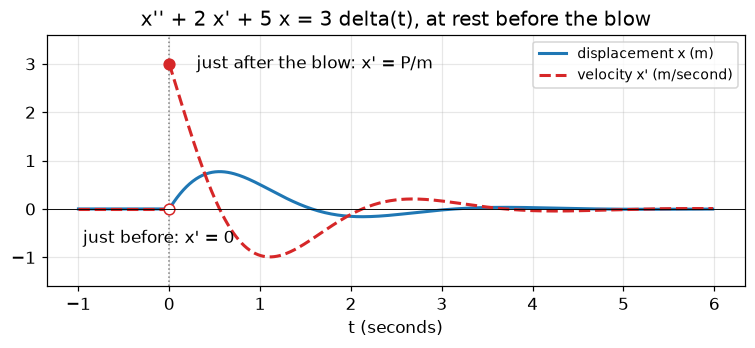

In [16]:
# this cell compares each step with the formulas of the text: your own numbers go in the cell after the figure
MASS, DAMPER, SPRING = 1.0, 2.0, 5.0        # kg, N s/m, N/m (the notebook's own numbers: keep them)
BLOW = 3.0                                  # the impulse P, in newton seconds
TEXT_HAMMER = ("this cell checks the formulas of the text, which are for m = 1, c = 2, k = 5, P = 3: "
               "put those numbers back, and try your own in the cell after the figure")
# the same numbers as whole numbers, for SymPy: 1, 2, 5, 3
mass, damper, spring, blow = (sp.nsimplify(number) for number in (MASS, DAMPER, SPRING, BLOW))
X_HAMMER = blow / (mass * s ** 2 + damper * s + spring)                             # step 2
hammer_formula = sp.inverse_laplace_transform(X_HAMMER, s, t)                       # SymPy's own inverse
print("x(t) =", hammer_formula, "  and  x'(t) =", sp.simplify(hammer_formula.diff(t)))
# (the digits of the text, on purpose)
assert sp.simplify(hammer_formula - sp.Rational(3, 2) * sp.exp(-t) * sp.sin(2 * t)) == 0, TEXT_HAMMER
assert hammer_formula.subs(t, 0) == 0, TEXT_HAMMER                                  # x = 0 at the blow
assert np.isclose(float(hammer_formula.diff(t).subs(t, 0)), BLOW / MASS), TEXT_HAMMER       # x' = P/m after


def hammer_x(t):
    # the displacement in meters: 0 before the blow, the formula of the text after it
    after = np.maximum(t, 0.0)
    return 3 / 2 * np.exp(-after) * np.sin(2 * after) * ol.step(t)


def hammer_velocity(t):
    # x'(t) in meters per second: 0 before the blow
    after = np.maximum(t, 0.0)
    return 3 / 2 * np.exp(-after) * (2 * np.cos(2 * after) - np.sin(2 * after)) * ol.step(t)


def hammer_h(t):
    # the response of this system to a blow with P = 1 (the impulse response h of the text below),
    return ol.impulse_response(t, MASS, DAMPER, SPRING)     # in meters for each newton second


T_HAMMER = (-1.0, 6.0)                      # seconds: the blow falls at t = 0
times = np.linspace(0.0, T_HAMMER[1], FINE_POINTS // 2 + 1)             # a point every 0.001 second
# the same motion with no delta function: free, from x = 0 with the velocity P/m (notebook 07)
free = ol.free_response(times, MASS, DAMPER, SPRING, 0.0, BLOW / MASS)
assert np.allclose(free, hammer_x(times)), TEXT_HAMMER
assert np.allclose(BLOW * hammer_h(times), hammer_x(times)), TEXT_HAMMER            # a blow P gives P h(t)
for s_value in S_CHECKS:                    # the answer, transformed forward, is X(s)
    assert np.isclose(ol.laplace_numeric(hammer_x, s_value), float(X_HAMMER.subs(s, s_value))), TEXT_HAMMER
print(f"largest displacement {hammer_x(times).max():.3f} m at t = {times[hammer_x(times).argmax()]:.3f} "
      f"seconds; velocity just after the blow {float(hammer_velocity(0.0)):g} m/second = P/m")

# drawing code: you can skip reading it
VELOCITY_HEIGHT = (-1.6, 3.6)
LABEL_AFTER = (0.3, 3.0)                    # where the two labels of the velocity are written
LABEL_BEFORE = (-0.95, -0.7)
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
draw_pieces(ax, hammer_x, T_HAMMER, "-", "C0", "displacement x (m)")
draw_pieces(ax, hammer_velocity, (T_HAMMER[0], 0.0, T_HAMMER[1]), "--", "C3", "velocity x' (m/second)")
ax.axvline(0.0, color="gray", linestyle=":", linewidth=1)                             # the blow
ax.plot(0.0, 0.0, "o", color="C3", markerfacecolor="white", markersize=POINT_SIZE)    # just before
ax.plot(0.0, BLOW / MASS, "o", color="C3", markersize=POINT_SIZE)                     # just after
ax.annotate("just after the blow: x' = P/m", (0.0, BLOW / MASS), xytext=LABEL_AFTER, va="center")
ax.annotate("just before: x' = 0", (0.0, 0.0), xytext=LABEL_BEFORE)
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_ylim(*VELOCITY_HEIGHT)
ax.set_xlabel("t (seconds)")
ax.set_title("x'' + 2 x' + 5 x = 3 delta(t), at rest before the blow")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows* the mass at rest until the blow at $t = 0$ (dotted line). The velocity (dashed) jumps
from 0 (empty dot, just before the blow) to 3 meters per second (full dot, just after), then oscillates
and dies out. The displacement (solid) has no jump, only a corner at $t = 0$: it rises to 0.771 m at
$t = 0.554$ seconds and dies out too. (Exercise 4.)

**The impulse response** $h(t)$ of an equation is its response, from rest, to the unit blow
$\delta(t)$, that is to $P = 1$ (Lebl, Section 6.4.3). For the hammer's system
$h(t) = \tfrac12e^{-t}\sin 2t$, and a blow of impulse $P$ gives $P\,h(t)$.
`ol.impulse_response(t, m, c, k)` computes $h(t)$: 0 for $t < 0$, and for $t \ge 0$ the free motion from
$x = 0$ with the velocity $1/m$. The next cell is for your own numbers.

velocity just after the blow: P/m = 3 m/second; largest |x| 0.771 m, first at t = 0.55 seconds


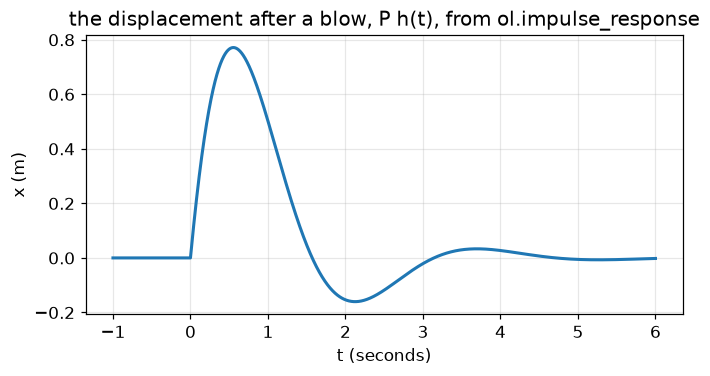

In [17]:
MY_MASS, MY_DAMPER, MY_SPRING, MY_BLOW = 1.0, 2.0, 5.0, 3.0     # kg, N s/m, N/m, newton seconds: try others
# (the mass must not be 0)
my_times = np.linspace(*T_HAMMER, FINE_POINTS)
my_x = MY_BLOW * ol.impulse_response(my_times, MY_MASS, MY_DAMPER, MY_SPRING)       # P h(t), in meters
NEARLY_LARGEST = 1e-6                       # a peak this near to the largest (in proportion) counts as it
size = np.abs(my_x)
first = int(np.argmax(size >= (1 - NEARLY_LARGEST) * size.max()))       # the first time it is reached
print(f"velocity just after the blow: P/m = {MY_BLOW / MY_MASS:g} m/second; "
      f"largest |x| {size.max():.3f} m, first at t = {my_times[first]:.2f} seconds")
plt.figure(figsize=SINGLE_FIGURE)
plt.plot(my_times, my_x, "-", color="C0", linewidth=2)
plt.xlabel("t (seconds)")
plt.ylabel("x (m)")
plt.title("the displacement after a blow, P h(t), from ol.impulse_response")
plt.show()

*The plot shows* the displacement of the hammer's mass again, now computed as $P\,h(t)$ from the four
numbers of the first line of the cell: change them (a mass of 2 kg, no damper, a harder blow) and run the
cell again.

## 6. Convolution

(Session 26.) Notebook 19 warned that the transform of a product is not the product of the transforms.
There is another way of combining two functions for which it is. *Lebl, formula (6.3.1):* the
**convolution** of $f$ and $g$ is the function

$$ (f * g)(t) = \int_0^t f(\tau)\,g(t - \tau)\,d\tau . $$

**How to read it.** $(f * g)(t)$ is read "f star g, at the time t": the star makes one new function out
of $f$ and $g$, and $(t)$ is where it is evaluated. (In Python the star `*` stays the ordinary product;
the convolution is `ol.convolution(f, g, t)`.) There are two letters. $t$ is fixed: it is the time at
which the answer is wanted.
$\tau$ runs from 0 to $t$: it is the variable of the integral, and it is gone at the end. For each
$\tau$, the value of $f$ at the time $\tau$ is multiplied by the value of $g$ at the time that is left,
$t - \tau$; the products are added up. The star is not a product: with $f = g = 1$,
$(1 * 1)(t) = \int_0^t 1 \cdot 1\,d\tau = t$, not 1.

*Lebl, Example 6.3.3:* $f(t) = t$ and $g(t) = e^{-t}$:

$$ (f * g)(t) = \int_0^t \tau\,e^{-(t - \tau)}\,d\tau = t - 1 + e^{-t} $$

(the book's answer, $e^{-t} + t - 1$; the integral, by parts, is in Section 9). At $t = 1$ it is
$e^{-1} = 0.368$. The same for $t = 3$, at four values of $\tau$ (the right panel of the figure below):

| $\tau$ | $f(\tau) = \tau$ | time left, $3 - \tau$ | $g(3 - \tau) = e^{-(3 - \tau)}$ | product |
|---|---|---|---|---|
| 0 | 0 | 3 | 0.050 | 0 |
| 1 | 1 | 2 | 0.135 | 0.135 |
| 2 | 2 | 1 | 0.368 | 0.736 |
| 3 | 3 | 0 | 1 | 3 |

As $\tau$ goes up, the time left goes down: $g$ is read from right to left, and that is why its curve
rises in the figure. The area under the products is $(f * g)(3) = 3 - 1 + e^{-3} = 2.050$.

`ol.convolution(f, g, t)` computes the integral numerically.

the convolutions, by ol.convolution
     t   f * g   the formula e^(-t) + t - 1   g * f   1 * 1
   0.5  0.106531               0.106531      0.106531  0.5000
     1  0.367879               0.367879      0.367879  1.0000
     2  1.135335               1.135335      1.135335  2.0000
     3  2.049787               2.049787      2.049787  3.0000


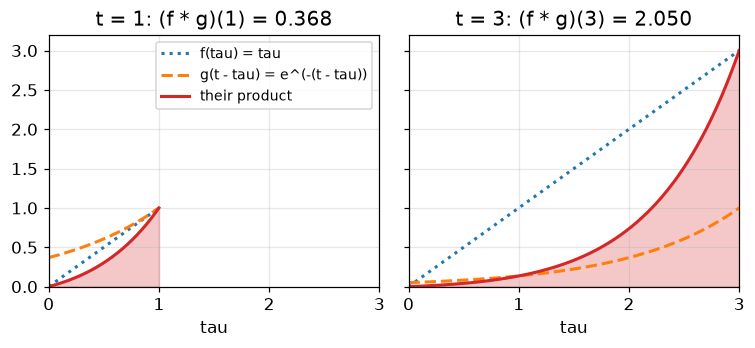

In [18]:
def ramp(t):
    return t                                # f(t) = t


def decay(t):
    return np.exp(-t)                       # g(t) = e^(-t)


T_VALUES = np.array([0.5, 1.0, 2.0, 3.0])   # the times t (keep np.array(...) around your own times)
# When f or g switches, give ol.convolution the times of the switches too, breaks=[...], as for
# ol.laplace_numeric: it tries to find switches by itself, but it does not promise to.
by_integral = ol.convolution(ramp, decay, T_VALUES)         # f * g, with f(t) = t and g(t) = e^(-t)
swapped = ol.convolution(decay, ramp, T_VALUES)             # g * f
ones = ol.convolution(lambda t: 1.0, lambda t: 1.0, T_VALUES)
print("the convolutions, by ol.convolution")
print("     t   f * g   the formula e^(-t) + t - 1   g * f   1 * 1")
for row in zip(T_VALUES, by_integral, np.exp(-T_VALUES) + T_VALUES - 1, swapped, ones):
    print("{:6g} {:9.6f} {:22.6f} {:13.6f} {:7.4f}".format(*row))
assert np.allclose(by_integral, np.exp(-T_VALUES) + T_VALUES - 1)       # Example 6.3.3
assert np.allclose(swapped, by_integral)                                # f * g = g * f
assert np.allclose(ones, T_VALUES)                                      # 1 * 1 = t

# drawing code: you can skip reading it
T_PAIR = (1.0, 3.0)                         # the two values of t of the figure
AREA_SHADE = 0.25
PRODUCT_HEIGHT = 3.2
fig, panels = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
for ax, t_fixed in zip(panels, T_PAIR):
    taus = np.linspace(0.0, t_fixed, CURVE_POINTS)
    ax.plot(taus, ramp(taus), ":", color="C0", linewidth=2, label="f(tau) = tau")
    ax.plot(taus, decay(t_fixed - taus), "--", color="C1", linewidth=2, label="g(t - tau) = e^(-(t - tau))")
    ax.plot(taus, ramp(taus) * decay(t_fixed - taus), "-", color="C3", linewidth=2, label="their product")
    ax.fill_between(taus, 0.0, ramp(taus) * decay(t_fixed - taus), color="C3", alpha=AREA_SHADE)
    ax.set_xlim(0.0, max(T_PAIR))
    ax.set_xticks(range(int(max(T_PAIR)) + 1))
    ax.set_ylim(0.0, PRODUCT_HEIGHT)
    ax.set_xlabel("tau")
    ax.set_title(f"t = {t_fixed:g}: (f * g)({t_fixed:g}) = {float(ol.convolution(ramp, decay, t_fixed)):.3f}")
panels[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows* the convolution of Example 6.3.3 at two times. On the horizontal axis is $\tau$, from 0
to $t$: $f(\tau) = \tau$ (dotted), $g(t - \tau)$ (dashed; it rises, as in the table, and it is 1 at
$\tau = t$, where no time is left), and their product (solid). The shaded area is $(f * g)(t)$: 0.368 for
$t = 1$ and 2.050 for $t = 3$. The table shows also that $f * g = g * f$ (Lebl).

**The theorem** (Lebl, Theorem 6.3.1): for $f$ and $g$ of exponential order (notebook 19; Lebl writes
"exponential type" here), **the transform of a convolution is the product of the transforms**,
$\mathcal{L}\{(f * g)(t)\} = F(s)\,G(s)$, for the values of $s$ at which $F(s)$ and $G(s)$ both exist. The
code checks it on the example ($F(s) = 1/s^2$, $G(s) = 1/(s + 1)$) at three values of $s$, beside the
transform of the ordinary product $te^{-t}$, which is another number. The theorem is used from right to
left: a transform that is a product, $F(s)G(s)$, comes from the convolution $f * g$.

In [19]:
print("     s   L{f * g}   F(s) G(s)   L{f g}, the ordinary product")
for s_value in S_CHECKS:
    of_convolution = ol.laplace_numeric(lambda t: np.exp(-t) + t - 1, s_value)
    product_of_transforms = (1 / s_value ** 2) * (1 / (s_value + 1))
    of_product = ol.laplace_numeric(lambda t: ramp(t) * decay(t), s_value)
    print(f"{s_value:6g} {of_convolution:10.6f} {product_of_transforms:11.6f} {of_product:10.6f}")
    assert np.isclose(of_convolution, product_of_transforms)
    assert np.isclose(of_product, 1 / (s_value + 1) ** 2)
    assert not np.isclose(of_product, product_of_transforms)

     s   L{f * g}   F(s) G(s)   L{f g}, the ordinary product
   0.5   2.666667    2.666667   0.444444
     1   0.500000    0.500000   0.250000
     4   0.012500    0.012500   0.040000


**The response to any input is the input convolved with the impulse response.** Take
$mx'' + cx' + kx = f(t)$ from rest. Step 1 gives $(ms^2 + cs + k)X(s) = F(s)$, so

$$ X(s) = H(s)\,F(s), \qquad H(s) = \frac{1}{ms^2 + cs + k} . $$

$H(s)$ is Lebl's **transfer function** (Section 6.2). For a unit blow $F(s) = 1$ and $X(s) = H(s)$: the
transfer function is the transform of the impulse response $h(t)$. For any other input, $X(s)$ is a
product of two transforms, so by the theorem

$$ x(t) = (f * h)(t) = \int_0^t f(\tau)\,h(t - \tau)\,d\tau $$

(Lebl, Section 6.4.3).

**Why, without transforms.**
1. Cut the time into short intervals of length $\Delta\tau$. During the interval at the time $\tau$ the
   force is a small blow of impulse $f(\tau)\Delta\tau$, force times time.
2. The coefficients $m$, $c$, $k$ do not change with time, so the system answers a blow at the time
   $\tau$ as it answers one at the time 0, only later, with $h$ delayed by $\tau$:
   $f(\tau)\Delta\tau \cdot h(t - \tau)$, where $t - \tau$ is the time that has passed since that blow.
3. A blow that falls after the time $t$ has not happened yet, and $h$ is 0 for a negative time: so only
   the blows from $\tau = 0$ to $\tau = t$ count.
4. The equation is linear, so the answers add up: $x(t) \approx$ the sum of
   $f(\tau)\,h(t - \tau)\,\Delta\tau$ over those blows. With shorter and shorter intervals the sum becomes
   the integral, and $\Delta\tau$ becomes $d\tau$.

The code tries it on the hammer's system with a force that fades, $f(t) = 8e^{-t}$ newtons, from rest:
the answer is $x(t) = 2e^{-t}(1 - \cos 2t)$ meters (by the four steps: Section 9).

X(s) = -2*(s + 1)/(s**2 + 2*s + 5) + 2/(s + 1)


blows   largest difference between their sum and x(t), in meters
    8      0.36636
   80      0.00351
  800      0.00000


ol.convolution(f, h, t), ol.forced_response and the formula agree: largest difference 6e-17 m


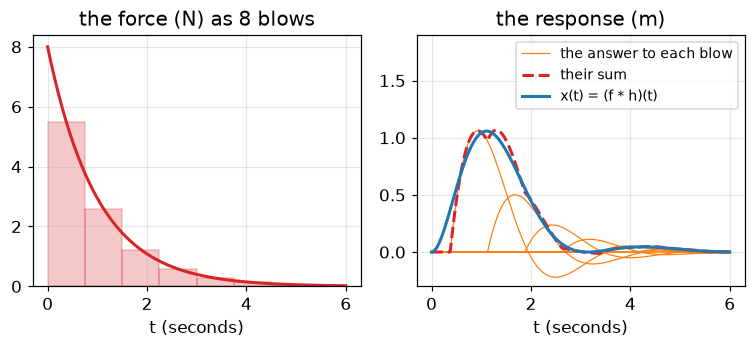

In [20]:
FORCE_START, FORCE_RATE = 8.0, 1.0          # f(t) = 8 e^(-t): newtons, 1/second (the text's: keep them)
TEXT_FADING = ("this cell checks the formula of the text, which is for the force 8 e^(-t) on the hammer's "
               "system (m = 1, c = 2, k = 5): put 8.0 and 1.0 back")
T_RESPONSE = 6.0                            # seconds
BLOWS_SHOWN = 8                             # the number of small blows of the figure
MIDDLE = 0.5                                # a blow stands for the force of its interval, at its middle
BLOWS_HEIGHT = (-0.3, 1.9)                  # room above the curves for the legend


def fading_force(t):
    return FORCE_START * np.exp(-FORCE_RATE * t)


def fading_response(t):
    return 2 * np.exp(-t) * (1 - np.cos(2 * t))             # the formula of the text, in meters


def one_blow(times, index, n_blows):
    # the answer to the blow number index (0, 1, ...) of n_blows: its impulse times the delayed h
    length = T_RESPONSE / n_blows           # the length of an interval, in seconds
    instant = (index + MIDDLE) * length     # the time of the blow
    return fading_force(instant) * length * hammer_h(times - instant)


def by_blows(times, n_blows):
    return sum(one_blow(times, index, n_blows) for index in range(n_blows))


force_start, force_rate = sp.nsimplify(FORCE_START), sp.nsimplify(FORCE_RATE)        # 8 and 1, for SymPy
fractions = sp.apart(force_start / (s + force_rate) * X_HAMMER / blow, s)           # F(s) times H(s)
print("X(s) =", fractions)
# (the digits of the text, on purpose)
assert sp.simplify(fractions - (2 / (s + 1) - 2 * (s + 1) / ((s + 1) ** 2 + 4))) == 0, TEXT_FADING
times = np.linspace(0.0, T_RESPONSE, CURVE_POINTS)
print("blows   largest difference between their sum and x(t), in meters")
for n_blows in (BLOWS_SHOWN, 10 * BLOWS_SHOWN, 100 * BLOWS_SHOWN):
    print(f"{n_blows:5d} {np.max(np.abs(by_blows(times, n_blows) - fading_response(times))):12.5f}")

# checking code: you can skip reading it; read what it prints
check_times = np.linspace(0.0, T_RESPONSE, CHECK_POINTS)
by_convolution = ol.convolution(fading_force, hammer_h, check_times)                # the integral f * h
third = ol.forced_response(check_times, MASS, DAMPER, SPRING, fading_force)         # notebook 14
assert np.allclose(by_convolution, fading_response(check_times)), TEXT_FADING
assert np.allclose(third, by_convolution)
print("ol.convolution(f, h, t), ol.forced_response and the formula agree: largest difference "
      f"{np.max(np.abs(by_convolution - fading_response(check_times))):.0e} m")

# drawing code: you can skip reading it
fig, (left, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
length = T_RESPONSE / BLOWS_SHOWN
instants = (np.arange(BLOWS_SHOWN) + MIDDLE) * length
left.bar(instants, fading_force(instants), width=length, color="C3", alpha=AREA_SHADE, edgecolor="C3")
left.plot(times, fading_force(times), "-", color="C3", linewidth=2)
left.set_xlabel("t (seconds)")
left.set_title(f"the force (N) as {BLOWS_SHOWN} blows")
for index in range(BLOWS_SHOWN):
    right.plot(times, one_blow(times, index, BLOWS_SHOWN), "-", color="C1", linewidth=0.8,
               label="the answer to each blow" if index == 0 else None)
right.plot(times, by_blows(times, BLOWS_SHOWN), "--", color="C3", linewidth=2, label="their sum")
right.plot(times, fading_response(times), "-", color="C0", linewidth=2, label="x(t) = (f * h)(t)")
right.set_ylim(*BLOWS_HEIGHT)
right.set_xlabel("t (seconds)")
right.set_title("the response (m)")
right.legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows*, left, the force $8e^{-t}$ and the 8 rectangles that replace it: each has the area, so
the impulse, of one small blow. Right: the 8 answers (thin lines), each a copy of $h$ that starts at the
time of its blow, with the size of its blow; their sum (dashed), with a corner at each blow; and the
solution $x(t)$ (thick, solid), which rises to 1.06 m at $t = 1.11$ seconds. With 8 blows the sum is
within 0.37 m of $x(t)$, with 80 blows within 0.004 m. (Resonance, seen once more: Exercise 3(vi).)

## 7. Where to go next

Left out, in Lebl: his Note on the derivative of the step (Section 6.4.2); integral equations of Volterra,
solved with the convolution theorem (Section 6.3.3); the bending of a beam under a load at one point, a
delta function in space (Section 6.4.4); partial differential equations (Section 6.5).

## 8. Exercises

Final answers are at the end; try first. After Session 25: Exercises 1(a)-(b), 2(a)-(b), 3(i)-(ii), 4(b);
after Session 26: the rest. Lebl's exercise numbers are those of the list at the end of his Chapter 6. A
formula is typed with SymPy, the letter `t` and the step `u` of this notebook, for example
`my_x = (t - 2) * u(t - 2)` or `my_x = sp.exp(-t) * sp.sin(2 * t)`.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) The value of $u(t - 3) - u(t - 5)$ at $t = 4$, and at $t = 6$.
* (b) True or False: $\mathcal{L}\{t^2\,u(t - 1)\} = e^{-s}\,\dfrac{2}{s^3}$.
* (c) (After Session 26.) A mass of 2 kg at rest is hit by a blow of 6 newton seconds. Its velocity
  right after the blow, in meters per second.
* (d) (After Session 26.) The value of $\mathcal{L}\{\delta(t - 2)\}$ at $s = 0$.

In [21]:
my_window_at_4 = None           # a number
my_window_at_6 = None           # a number
my_shift_rule = None            # True or False
my_velocity = None              # a number, in meters per second
my_delta_at_0 = None            # a number
# ---- your answers go above this line; the lines below check them (nothing to change) ----

WINDOW_1A = (3.0, 5.0)                      # u(t - 3) - u(t - 5)
TIMES_1A = (4.0, 6.0)
at_4, at_6 = (float(ol.step(time, WINDOW_1A[0]) - ol.step(time, WINDOW_1A[1])) for time in TIMES_1A)
ol.check("Exercise 1a, at t = 4", my_window_at_4, at_4)
ol.check("Exercise 1a, at t = 6", my_window_at_6, at_6)
CUT_1B = 1.0                                # t^2 u(t - 1)
CHECK_S_1 = (1.0, 2.0)                      # the two sides are compared at these values of s
same_at_every_s = all(
    np.isclose(ol.laplace_numeric(lambda t: t ** 2 * float(ol.step(t, CUT_1B)), s_value, breaks=[CUT_1B]),
               np.exp(-CUT_1B * s_value) * 2 / s_value ** 3)
    for s_value in CHECK_S_1)
ol.check("Exercise 1b", my_shift_rule, same_at_every_s)
if my_shift_rule is True and not same_at_every_s:
    print("   (is t^2 u(t - 1) a delayed t^2, or t^2 cut off? See Section 3)")
MASS_1C, BLOW_1C = 2.0, 6.0                 # kg, newton seconds
SOON = 1e-6                                 # seconds: just after the blow
# the mass alone, m x'' = P delta(t): the velocity just after the blow is the slope of P h(t) at t = 0
velocity_1c = BLOW_1C * float(ol.impulse_response(SOON, MASS_1C, 0.0, 0.0)) / SOON
assert np.isclose(velocity_1c, BLOW_1C / MASS_1C)
ol.check("Exercise 1c", my_velocity, BLOW_1C / MASS_1C)
DELAY_1D, S_1D = 2.0, 0.0                   # delta(t - 2), at s = 0
ol.check("Exercise 1d", my_delta_at_0, np.exp(-DELAY_1D * S_1D));

Exercise 1a, at t = 4: no answer yet (replace None with your value)
Exercise 1a, at t = 6: no answer yet (replace None with your value)
Exercise 1b: no answer yet (replace None with your value)
Exercise 1c: no answer yet (replace None with your value)
Exercise 1d: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

**(a)** *Lebl, Exercise 6.2.13.* Write with step functions the function that is 0 for $t < 1$, $t - 1$
for $1 \le t < 2$, and 1 for $2 \le t$. First step: a window for the middle piece, and one step for the
last piece.

**(b)** *Lebl, Exercise 6.2.6.* Solve $x'' + x = u(t - 1)$, $x(0) = 0$, $x'(0) = 0$. First step:
$(s^2 + 1)X(s) = e^{-s}/s$; Section 4 has the partial fractions.

**(c)** (After Session 26.) *Lebl, Exercise 6.4.3.* "A pulse can come later and can be bigger": solve
$x'' + 4x = 4\,\delta(t - 1)$, $x(0) = 0$, $x'(0) = 0$. First step: $(s^2 + 4)X(s) = 4e^{-s}$.

**(d)** (After Session 26.) *Lebl, Exercise 6.3.10.* Compute $f * g$ for $f(t) = \cos t$ and
$g(t) = e^{-t}$. First step: $(f * g)(t) = e^{-t}\displaystyle\int_0^t e^{\tau}\cos\tau\,d\tau$, and
$\displaystyle\int e^{\tau}\cos\tau\,d\tau = \tfrac12e^{\tau}(\cos\tau + \sin\tau)$.

If an answer stops with an error that names `ImmutableDenseNDimArray`, or says that something is
"not callable", run the small cell above the answer cell and try again: a cell of Exercise 3 has given
`t` or `u` another value.

In [22]:
# SymPy's letters t and s and the step u again, for Exercise 2 (nothing to change here: run this cell
# before the next one, every time: a cell of Exercise 3 may have given these names to something else)
t, s = sp.symbols("t s", positive=True)
u = step_in_formulas

In [23]:
my_cases_2a = None              # a formula in t, with u(t - 1) and u(t - 2)
my_switch_2b = None             # a formula in t, with u(t - 1)
my_blow_2c = None               # a formula in t, with u(t - 1)
my_convolution_2d = None        # a formula in t
# ---- your answers go above this line; the lines below check them (nothing to change) ----

t, s = sp.symbols("t s", positive=True)     # SymPy's t and s, and the step u, for the formulas below
u = step_in_formulas
CHECK_T_2 = (0.15, 5.55)                    # formulas are compared at 7 times between these: none at a jump,
sample_times = np.linspace(*CHECK_T_2, ol.FORMULA_SAMPLES)                 # one after 1, one before 2


def same_values(mine, other):
    # True when the two formulas agree at the times of the check
    try:
        return bool(np.allclose(sp.lambdify(t, mine)(sample_times) + 0 * sample_times,
                                sp.lambdify(t, other)(sample_times) + 0 * sample_times))
    except Exception:                       # not a formula in t: ol.check_formula will say what is wrong
        return False


def check_with_hints(label, mine, expected, hints):
    # as ol.check_formula, with a sentence of its own for each usual mistake: (a wrong formula, its sentence)
    for wrong, sentence in hints:
        if mine is not None and not isinstance(mine, (str, bytes)) and same_values(mine, wrong):
            print(f"{label}: not yet ({sentence})")
            return False
    return ol.check_formula(label, mine, expected, t, CHECK_T_2)


NO_STEP = "before t = 1 nothing has moved: multiply by u(t - 1)"
CUT_OFF = "cut off before t = 1, not delayed: write t - 1 in place of every t"

expected_2a = (t - 1) * (u(t - 1) - u(t - 2)) + u(t - 2)                   # the answer printed in the book
EDGES_2A = (1.0, 2.0)                       # 0 before the first, t - 1 between them, 1 after the second
cases_2a = np.select([sample_times < EDGES_2A[0], sample_times < EDGES_2A[1]],
                     [0.0, sample_times - EDGES_2A[0]], 1.0)
assert np.allclose(sp.lambdify(t, expected_2a)(sample_times), cases_2a)
check_with_hints("Exercise 2a", my_cases_2a, expected_2a, [
    ((t - 1) * u(t - 1) + u(t - 2),
     "the piece t - 1 is never switched off: give it a window, u(t - 1) - u(t - 2)")])

SWITCH_2B = 1.0                             # x'' + x = u(t - 1)
expected_2b = (1 - sp.cos(t - 1)) * u(t - 1)
assert np.allclose(sp.lambdify(t, expected_2b)(sample_times),              # the step convolved with h = sin t
                   ol.convolution(lambda t: ol.step(t, SWITCH_2B), np.sin, sample_times, breaks=[SWITCH_2B]))
check_with_hints("Exercise 2b", my_switch_2b, expected_2b, [
    ((1 - sp.cos(t)) * u(t - 1), "this is 1 - cos t " + CUT_OFF), (1 - sp.cos(t - 1), NO_STEP)])

SPRING_2C, BLOW_2C, DELAY_2C = 4.0, 4.0, 1.0                               # x'' + 4x = 4 delta(t - 1)
expected_2c = 2 * sp.sin(2 * (t - 1)) * u(t - 1)
assert np.allclose(sp.lambdify(t, expected_2c)(sample_times),              # a blow of size 4, delayed by 1
                   BLOW_2C * ol.impulse_response(sample_times - DELAY_2C, 1.0, 0.0, SPRING_2C))
check_with_hints("Exercise 2c", my_blow_2c, expected_2c, [
    (2 * sp.sin(2 * (t - 1)), NO_STEP), (2 * sp.sin(2 * t) * u(t - 1), "this is 2 sin 2t " + CUT_OFF),
    (4 * sp.sin(2 * (t - 1)) * u(t - 1),
     "the row of sin 2t has a 2 on top: 4/(s^2 + 4) is 2 times 2/(s^2 + 4)")])

expected_2d = (sp.cos(t) + sp.sin(t) - sp.exp(-t)) / 2                     # the answer printed in the book
assert np.allclose(sp.lambdify(t, expected_2d)(sample_times),
                   ol.convolution(np.cos, lambda t: np.exp(-t), sample_times))
ol.check_formula("Exercise 2d", my_convolution_2d, expected_2d, t, CHECK_T_2);

Exercise 2a: no answer yet (replace None with your formula)
Exercise 2b: no answer yet (replace None with your formula)
Exercise 2c: no answer yet (replace None with your formula)
Exercise 2d: no answer yet (replace None with your formula)


### Exercise 3 - Explore

* (i) *(Lebl, Exercise 6.2.14)* The book's answer to $x'' - x = (t^2 - 1)\,u(t - 1)$, $x(0) = 1$,
  $x'(0) = 2$ is $x(t) = (2e^{t - 1} - t^2 - 1)\,u(t - 1) - \tfrac12e^{-t} + \tfrac32e^{t}$. Check it with
  `ol.forced_response` (the template in the cell below).
* (ii) The rocket of Section 4 is fired twice, each time for 4 seconds: from $t = 1$, and again from
  $t = T$. With `rocket_response` the displacement is
  `rocket_response(times) + rocket_response(times - (T - 1))`. Draw it for $T = 8$. Then find a $T > 5$
  for which the mass is at rest after the second firing.
* (iii) (After Session 26.) *(Lebl, Exercises 6.4.9 and 6.4.10)* Find the impulse response of
  $x'' = \delta(t)$ and of $x' + ax = \delta(t)$, by the four steps. Check the first with
  `ol.impulse_response(times, 1, 0, 0)`. Why does `ol.impulse_response(times, 0, 1, 2)` give an error?
  (In the error sentence, "a" is the first number after the times, the coefficient of $x''$; it is not
  the $a$ of this exercise.)
* (iv) (After Session 26.) *(Lebl, Exercise 6.3.12)* Solve $x'' + x = \sin t$, $x(0) = 0$, $x'(0) = 0$
  with the convolution: `ol.convolution(np.sin, np.sin, times)`. Compare with the book's answer,
  $\tfrac12(\sin t - t\cos t)$.
* (v) (After Session 26.) Two blows on the mass of Section 4: $x'' + x = \delta(t) + \delta(t - a)$,
  from rest. The response is `ol.impulse_response(times, 1, 0, 1) +
  ol.impulse_response(times - a, 1, 0, 1)`. For which time $a$ does the second blow stop the mass?
  Draw the response for $a = 2$ and for your $a$.
* (vi) (After Session 26.) *(Lebl, Example 6.3.4: resonance)* For $x'' + \omega_0^2x = \cos\omega_0t$
  from rest the impulse response is $\sin(\omega_0t)/\omega_0$, and the convolution gives
  $x(t) = \dfrac{t}{2\omega_0}\sin\omega_0t$. Check it for $\omega_0 = 2$ with
  `ol.convolution(lambda t: np.cos(2 * t), lambda t: ol.impulse_response(t, 1, 0, 4), times)`. Where
  did notebook 15 meet the factor $t$?

In [24]:
# your code here. Call your times "times": t is SymPy's letter in this notebook.
# (i) a template: select the seven lines below and press Ctrl + / (it removes the # and the space
# after it), then run the cell
# times = np.linspace(0.0, 3.0, 13)
# book = ((2 * np.exp(times - 1) - times ** 2 - 1) * ol.step(times, 1)
#         - np.exp(-times) / 2 + 3 * np.exp(times) / 2)
# found = ol.forced_response(times, 1, 0, -1, lambda t: (t ** 2 - 1) * float(ol.step(t, 1)), 1, 2)
# print("largest difference:", np.max(np.abs(found - book)))
# plt.plot(times, book)
# plt.show()
# (ii) a template, for T = 8:
# times = np.linspace(0.0, 30.0, 600)
# plt.plot(times, rocket_response(times) + rocket_response(times - (8 - 1)))
# plt.show()
# (v) a template, for a = 2:
# times = np.linspace(0.0, 20.0, 400)
# plt.plot(times, ol.impulse_response(times, 1, 0, 1) + ol.impulse_response(times - 2, 1, 0, 1))
# plt.show()

### Exercise 4 - Explain

**(a)** (After Session 26; two or three sentences.) The hammer problem of Section 5 asks for
$x'(0) = 0$, and its solution $x(t) = \tfrac32e^{-t}\sin 2t$ has $x'(0) = 3$. Why is this not a
contradiction? First step: what is the velocity of the mass at $t = -0.001$ seconds, and at
$t = +0.001$ seconds?

**(b)** (After Session 25: its theory exercise; Lebl, Exercise 6.2.9.) Why does a delay become the
factor $e^{-as}$? Show the second shifting property, $\mathcal{L}\{f(t - a)\,u(t - a)\} = e^{-as}F(s)$
for $a \ge 0$. First step: the step makes the integral start at $a$; then use the new variable
$v = t - a$.

## 9. Answers

Final answers only; full solutions are given after the sessions.

<details>
<summary>Click to open (after trying)</summary>

1. (a) 1 at $t = 4$ ($1 - 0$) and 0 at $t = 6$ ($1 - 1$). (b) False: $t^2\,u(t - 1)$ is cut off, not
   delayed. With $t^2 = (t - 1)^2 + 2(t - 1) + 1$ the transform is
   $e^{-s}\Big(\dfrac{2}{s^3} + \dfrac{2}{s^2} + \dfrac1s\Big)$. (c) $P/m = 6/2 = 3$ meters per second.
   (d) $e^{-2s}$ at $s = 0$: 1.
2. (a) `(t - 1) * (u(t - 1) - u(t - 2)) + u(t - 2)` (the book's answer); the same function is
   `(t - 1) * u(t - 1) - (t - 2) * u(t - 2)`. The recipe for a function given by cases: multiply each
   formula by the window of its interval, and add. Lebl's own example (Section 6.2), the function that is
   $t$ for $0 \le t < 1$, $-t + 2$ for $1 \le t < 2$ and 0 otherwise, is
   $t\big(u(t) - u(t - 1)\big) + (-t + 2)\big(u(t - 1) - u(t - 2)\big)$; at $t = 1.5$ only the second
   window is 1, and the value is $-1.5 + 2 = 0.5$. (b) `(1 - sp.cos(t - 1)) * u(t - 1)`: the step response
   $1 - \cos t$ of Section 4, delayed by 1. (c) `2 * sp.sin(2 * (t - 1)) * u(t - 1)`:
   $X(s) = 2e^{-s}\dfrac{2}{s^2 + 4}$, that is $2\sin 2t$ delayed by 1; the mass starts to move at
   $t = 1$. (d) `(sp.cos(t) + sp.sin(t) - sp.exp(-t)) / 2` (the book's answer).
3. (i) The largest difference is less than $10^{-9}$. (ii) For $T = 8$ the mass oscillates
   between $-3.41$ and $3.41$ after the second firing. Why: after one firing of $d$ seconds from
   $t = 1$, for $t \ge 1 + d$,
   $x(t) = \cos(t - 1 - d) - \cos(t - 1) = 2\sin\dfrac{d}{2}\,\sin\Big(t - 1 - \dfrac{d}{2}\Big)$,
   by the identity $\cos A - \cos B = -2\sin\frac{A + B}{2}\sin\frac{A - B}{2}$ with $A = t - 1 - d$ and
   $B = t - 1$. The amplitude after the stop is $2\,|\sin(d/2)|$ (the slider of Section 4): 1.82 for
   $d = 4$; the largest, 2, for $d = \pi$, when the rocket stops with the mass farthest out, at $x = 2$;
   and 0 for $d = 2\pi$, $4\pi$, ... So after the first firing ($d = 4$)
   $x = 2\sin 2\,\sin(t - 3)$; the second adds $2\sin 2\,\sin(t - 3 - (T - 1))$, which cancels the first
   when $T - 1$ is an odd multiple of $\pi$: $T = 1 + 3\pi \approx 10.42$ (and $1 + 5\pi$, ...;
   $1 + \pi$ is not larger than 5).
   (iii) $X(s) = 1/s^2$ gives $x(t) = t$: the mass moves away at constant velocity. $X(s) = 1/(s + a)$
   gives $x(t) = e^{-at}$ (the book's answers). The second equation is of first order:
   `ol.impulse_response` is for $mx'' + cx' + kx$ with $m \ne 0$, and says so (its sentence calls that
   first coefficient "a").
   (iv) $X(s) = \dfrac{1}{s^2 + 1}\cdot\dfrac{1}{s^2 + 1}$, so $x = \sin t * \sin t$; the two agree to
   at least 8 digits. The factor $t$ is resonance.
   (v) $a = \pi$ (and $3\pi$, ...): $\sin t + \sin(t - \pi) = 0$ for $t \ge \pi$. At $t = \pi$ the
   mass passes through $x = 0$ with velocity $\cos\pi = -1$, and the blow adds $+1$.
   (vi) The two agree to at least 8 digits; at $t = 3$ both are $-0.2096$. Notebook 15: a force with the
   natural frequency of the system gives an oscillation that grows like $t$ (resonance); here the
   factor $t$ comes out of the integral, with no special rule.
4. (a) The initial values say how the mass is just before the blow: at rest, with velocity 0 (also at
   $t = -0.001$ seconds). The formula holds after the blow: at $t = +0.001$ seconds the velocity is
   2.99 meters per second. The blow changes the velocity by $P/m = 3$ meters per second in no time (the
   delta function is what does it; no ordinary force can); the position cannot jump, so $x(0) = 0$ holds
   on both sides.
   (b) The step makes the integral start at $a$. Then $v = t - a$: so $t = v + a$ and $dt = dv$; when
   $t = a$, $v = 0$, and when $t \to \infty$, $v \to \infty$; and $f(t - a)$ becomes $f(v)$:
   $\displaystyle\int_0^\infty e^{-st}f(t - a)\,u(t - a)\,dt = \int_a^\infty e^{-st}f(t - a)\,dt
   = \int_0^\infty e^{-s(v + a)}f(v)\,dv = e^{-as}\int_0^\infty e^{-sv}f(v)\,dv = e^{-as}F(s)$,
   because $e^{-s(v + a)} = e^{-as}e^{-sv}$, the factor $e^{-as}$ does not contain $v$, and the last
   integral is the definition of $F(s)$ with the letter $v$ for $t$.

**At home: the computations that the text left out.**

* *The transform of a step* (Section 2). Before the time $a$ the function is 0, so the integral starts
  at $a$:
  $\displaystyle\mathcal{L}\{u(t - a)\} = \int_0^\infty e^{-st}u(t - a)\,dt
  = \int_0^a e^{-st}\cdot 0\,dt + \int_a^\infty e^{-st}\cdot 1\,dt
  = \Big[-\frac{e^{-st}}{s}\Big]_a^\infty = 0 - \Big(-\frac{e^{-as}}{s}\Big) = \frac{e^{-as}}{s}$.
  (At the upper end $e^{-st} \to 0$ as $t \to \infty$, because $s > 0$: that is the 0.)
* *Slider 2 by a formula* (Section 5). After the pulse, for $t \ge b$, as for the rocket,
  $x(t) = \dfrac{\cos(t - b) - \cos t}{b} = \dfrac{2}{b}\sin\dfrac{b}{2}\,\sin\Big(t - \dfrac{b}{2}\Big)$,
  and $\dfrac2b\sin\dfrac b2 \to 1$ as $b \to 0$, because $\sin z \approx z$ for a small number $z$
  (near $z = 0$ the curve is almost its tangent line; try $z = 0.01$ on a calculator). In the same way
  $e^{-z} \approx 1 - z$, which is why the transform $(1 - e^{-bs})/(bs)$ of the pulse tends to 1.
* *Example 6.3.3 by parts* (Section 6). $g(t - \tau) = e^{-(t - \tau)} = e^{-t}e^{\tau}$, and $e^{-t}$
  does not contain $\tau$, so it comes out of the integral:
  $(f * g)(t) = e^{-t}\displaystyle\int_0^t \tau\,e^{\tau}\,d\tau$. By parts (video R03), differentiating
  the factor $\tau$ and integrating the factor $e^{\tau}$:
  $\displaystyle\int_0^t \tau e^{\tau}d\tau = \big[\tau e^{\tau}\big]_0^t - \int_0^t 1 \cdot e^{\tau}d\tau
  = te^t - (e^t - 1)$. Times $e^{-t}$: $t - 1 + e^{-t}$.
* *The fading force by the four steps* (Section 6).
  $X(s) = H(s)F(s) = \dfrac{1}{s^2 + 2s + 5}\cdot\dfrac{8}{s + 1}
  = \dfrac{A}{s + 1} + \dfrac{Bs + C}{s^2 + 2s + 5}$. Multiply by the two denominators:
  $8 = A(s^2 + 2s + 5) + (Bs + C)(s + 1)$. With $s = -1$: $8 = 4A$, so $A = 2$. The powers $s^2$:
  $0 = A + B$, so $B = -2$. The constants: $8 = 5A + C$, so $C = -2$. The second fraction is
  $\dfrac{-2s - 2}{(s + 1)^2 + 4} = -\dfrac{2(s + 1)}{(s + 1)^2 + 4}$, the transform of
  $-2e^{-t}\cos 2t$; the first, $\dfrac{2}{s + 1}$, is the transform of $2e^{-t}$. So
  $x(t) = 2e^{-t} - 2e^{-t}\cos 2t$.

</details>

**Where to go next:** notebook 21, series solutions.